# Vial color and recipe-transition recovery

This notebook runs the real-data workflow in `changeover_guard.model_workflow`.
It measures full-vial color, audits recipe boundaries, plots observed recovery,
counts independent sessions, and fits only supported optical-density models.

**Available evidence:** the committed October 29 CSVs contain 27 vial labels and
six recipe changes in one session, 1,187 aligned images and three recordings.
The camera controls needed for calibration and production decisions are absent.
The shipped assessment samples 26 vials; 16 pass measurement quality checks.
These are real-data exploratory results. Controlled fixtures are used only in tests.

Read [the calibration and schema guide](../docs/transition_analysis.md). Select
the repository `.venv` kernel after `uv sync --locked --group analysis`.

In [6]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import sys

_repo_root = next(
    (path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (path / 'pyproject.toml').exists()),
    None,
)
if _repo_root is None:
    raise FileNotFoundError('Could not find the repository root (pyproject.toml).')

sys.path.insert(0, str(_repo_root / 'src'))
from changeover_guard.model_workflow import default_config, run_workflow

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists() and (ROOT.parent / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Run from the repository or notebooks directory.'
pd.set_option('display.max_columns', 30)
print('Repository:', ROOT)

Repository: C:\Users\rubioreyesa\OneDrive - Milwaukee School of Engineering\School Work\Fall 2026\Innovation Lab\main_project\msoe-ai-club-rockwell-automation-nvidia-hackath-cade-rousseau-s-team-f95bb31640


## 1. Configure sessions and validate the clock

The default detects `data/10_29_26/vial_filled/labels/vial_recipes.csv` and
`vial_fill_frame_labels.csv`, as well as original video-5 names. Edit the video
path if more than one recording is present or it lives elsewhere.

New labels use `start_time/end_time`. The frame labels establish
`video_origin = timestamp - video_s`. For the supplied example, `2:04:48` starts
at **112.61 wall-clock elapsed seconds**, not at 7,488 seconds. This differs from
the MP4 container clock in this recording. Auto mode uses the aligned timestamped
stills. Original elapsed-second video-5 labels keep their video sampling path.

Add one `sessions` entry per independently collected recording, not per crop or
frame. Optional chart, repeatability, clean controls and calibration paths are
documented in the guide. All relative paths resolve from `ROOT`.

In [7]:
CONFIG_FILE = ROOT / 'work' / 'transition_config.json'
CONFIG = json.loads(CONFIG_FILE.read_text(encoding='utf-8')) if CONFIG_FILE.exists() else default_config(ROOT)

# Example overrides for your local checkout:
# CONFIG['sessions'][0]['recipe_csv'] = 'data/10_29_26/vial_filled/labels/vial_recipes.csv'
# CONFIG['sessions'][0]['frame_csv'] = 'data/10_29_26/vial_filled/labels/vial_fill_frame_labels.csv'
# CONFIG['sessions'][0]['video'] = 'data/10_29_26/vial_filled/videos/your_recording.mp4'
# CONFIG['chart_csv'] = 'work/vial_chart.csv'
# CONFIG['calibration_file'] = 'outputs/transition_analysis/<run>/vial_camera_calibration.json'
# CONFIG['repeatability_csv'] = 'work/stable_vial_controls.csv'
# CONFIG['clean_controls_csv'] = 'work/verified_clean_controls.csv'

print(json.dumps(CONFIG, indent=2))

{
  "output_dir": "outputs/transition_analysis",
  "threshold": 2.2,
  "consecutive": 3,
  "calibration": {
    "camera_id": "vial_fill",
    "matrix": [
      [
        1.0,
        0.0,
        0.0
      ],
      [
        0.0,
        1.0,
        0.0
      ],
      [
        0.0,
        0.0,
        1.0
      ]
    ],
    "reference_size": [
      640,
      480
    ],
    "liquid_roi": [
      300,
      335,
      324,
      370
    ],
    "reference_roi": null,
    "reference_rgb": null,
    "settings_locked": false,
    "alignment_reviewed": false,
    "validation_delta_e": [],
    "chart_sha256": null
  },
  "calibration_file": null,
  "chart_csv": null,
  "repeatability_csv": null,
  "clean_controls_csv": null,
  "baseline_id": null,
  "sessions": [
    {
      "session_id": "10_29_26",
      "recipe_csv": "C:\\Users\\rubioreyesa\\OneDrive - Milwaukee School of Engineering\\School Work\\Fall 2026\\Innovation Lab\\main_project\\msoe-ai-club-rockwell-automation-nvidia-hackath-

In [8]:
result = run_workflow(CONFIG, ROOT)
report = result['report']
OUTPUT = result['output_dir']
measurements, curves, summary = result['measurements'], result['curves'], result['summary']
display(pd.Series({
    'status': report['status'], 'measured_vials': report['measured_vials'],
    'usable_vials': report['usable_vials'],
    'production_enabled': report['production_decisions_enabled'],
    'output_directory': str(OUTPUT),
}))
display(pd.DataFrame(report['label_audits']))
display(pd.Series(report['label_inventory']))
display(result['label_runs'])
display(result['label_transitions'])
if report['missing_inputs']:
    print('Missing inputs:', *report['missing_inputs'], sep='\n  ')
if report['errors']:
    display(pd.DataFrame(report['errors']))

status                                                         measured
measured_vials                                                       26
usable_vials                                                         16
production_enabled                                                False
output_directory      C:\Users\rubioreyesa\OneDrive - Milwaukee Scho...
dtype: object

,session_id,timing,frame_labels,video_container_duration_s,last_labeled_end_s,label_clock_exceeds_container,measurement_source
0,10_29_26,"{'schema': 'wall_clock', 'video_origin': '2026...","{'status': 'audited', 'frames': 1187, 'labeled...",1956.3,2128.61,True,timestamped_stills


vials                                                                   27
sessions                                                                 1
recipe_runs                                                              7
transitions                                                              6
distinct_recipes                                                         3
directed_pairs           [{'previous_recipe_id': 1, 'next_recipe_id': 2...
unobserved_directions                             [[1, 3], [2, 1], [3, 2]]
mixture_recipes                                                          0
unobservable_vials                                       [10_29_26/vial10]
operator_error_vials                     [10_29_26/vial8, 10_29_26/vial10]
note                     Counts describe labels. Multiple changes withi...
dtype: object

,session_id,run_id,recipe_id,first_vial,last_vial,labeled_vials,timed_vials,operator_error_vials,requested_total_ml,volume_history_usable,start_s,end_s,t100_ml,t200_ml,t400_ml
0,10_29_26,10_29_26/run1,1,1,5,5,5,0,375.0,True,112.61,432.61,75.0,0.0,0.0
1,10_29_26,10_29_26/run2,2,6,10,5,4,2,225.0,False,462.61,NaN,0.0,45.0,0.0
2,10_29_26,10_29_26/run3,3,11,12,2,2,0,150.0,True,908.61,995.61,0.0,0.0,75.0
3,10_29_26,10_29_26/run4,1,13,16,4,4,0,300.0,True,1038.61,1285.61,75.0,0.0,0.0
4,10_29_26,10_29_26/run5,2,17,19,3,3,0,135.0,True,1376.61,1525.61,0.0,45.0,0.0
5,10_29_26,10_29_26/run6,3,20,22,3,3,0,225.0,True,1562.61,1709.61,0.0,0.0,75.0
6,10_29_26,10_29_26/run7,1,23,27,5,5,0,375.0,True,1811.61,2128.61,75.0,0.0,0.0


,transition_id,session_id,previous_recipe_id,next_recipe_id,previous_run_id,first_vial,next_run_labeled_vials,next_run_timed_vials,previous_volume_history_usable,next_volume_history_usable
0,10_29_26/run2,10_29_26,1,2,10_29_26/run1,6,5,4,True,False
1,10_29_26/run3,10_29_26,2,3,10_29_26/run2,11,2,2,False,True
2,10_29_26/run4,10_29_26,3,1,10_29_26/run3,13,4,4,True,True
3,10_29_26/run5,10_29_26,1,2,10_29_26/run4,17,3,3,True,True
4,10_29_26/run6,10_29_26,2,3,10_29_26/run5,20,3,3,True,True
5,10_29_26/run7,10_29_26,3,1,10_29_26/run6,23,5,5,True,True


## 2. Inspect full-vial alignment and the liquid ROI

For the new collection, each vial uses the nearest matching timestamped still
inside its final 2.5 seconds, with source time and image hash retained. Its single
still gives no temporal repeatability estimate. The MP4 runs 1,956.3 container
seconds but the image index spans 2,372 wall-clock seconds. Treating them as the
same clock would inspect the wrong vial. Original video labels use three decoded
samples near the end time. Bad samples stay in sequence and break recovery streaks.

The committed labels explicitly mark vial 10 as unobservable during a blackout;
its timing stays missing. Requested throughput after an operator error remains
unsupported until measured volumes establish it. No time window is invented.

Review the contact sheets at **every recipe change** before setting
`alignment_reviewed`. Spatial spread and adjacent-frame variation are quality
diagnostics; neither proves camera repeatability. All contact pages are saved
beside the CSV exports, including those not displayed below.

,session_id,vial,recipe_id,start_s,end_s,sample_times_s,actual_source_times_s,source_clock,source_clock_verified,source_timestamp_age_s,r,g,b,L,a,lab_b,usable,quality_flags,volume_source
0,10_29_26,1,1,112.61,141.61,[141.01000000000002],[139.984],wall_clock_relative_seconds,True,0.016,54.0,45.0,16.0,18.793956,-0.226341,19.866979,True,,requested_proxy
1,10_29_26,2,1,184.61,213.61,[213.01000000000002],[211.999],wall_clock_relative_seconds,True,0.001,64.0,45.0,16.0,20.061568,5.107368,21.654849,True,,requested_proxy
2,10_29_26,3,1,256.61,286.61,[286.01],[285.999],wall_clock_relative_seconds,True,0.001,52.0,37.0,12.0,15.901101,3.775115,18.315080,False,uneven_liquid_patch,requested_proxy
3,10_29_26,4,1,330.61,359.61,[359.01],[357.969],wall_clock_relative_seconds,True,0.031,59.0,44.0,15.0,19.080665,3.041024,20.901614,True,,requested_proxy
4,10_29_26,5,1,403.61,432.61,[432.01],[431.967],wall_clock_relative_seconds,True,0.033,60.0,45.0,14.0,19.512831,2.829763,21.950809,True,,requested_proxy
5,10_29_26,6,2,462.61,493.61,[493.01],[491.988],wall_clock_relative_seconds,True,0.012,64.0,30.0,0.0,15.585843,14.099264,23.240889,False,clipped_dark_channels,requested_proxy
6,10_29_26,7,2,519.61,552.61,[552.01],[551.97],wall_clock_relative_seconds,True,0.030,57.0,9.0,0.0,9.525678,22.885070,14.826378,False,clipped_dark_channels,requested_proxy
7,10_29_26,8,2,579.61,610.61,[610.01],[609.755],wall_clock_relative_seconds,True,0.245,56.0,34.0,6.0,15.477626,7.587042,20.389551,False,label_status_not_ok,requested_proxy
8,10_29_26,9,2,636.61,676.61,[676.01],[669.21],wall_clock_relative_seconds,False,6.790,57.0,7.0,0.0,9.174180,23.859259,14.323842,False,clipped_dark_channels;stale_camera_frame,requested_proxy
9,10_29_26,10,2,NaN,NaN,[],[],wall_clock_relative_seconds,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,label_status_not_ok;unobservable_vial_window,requested_proxy


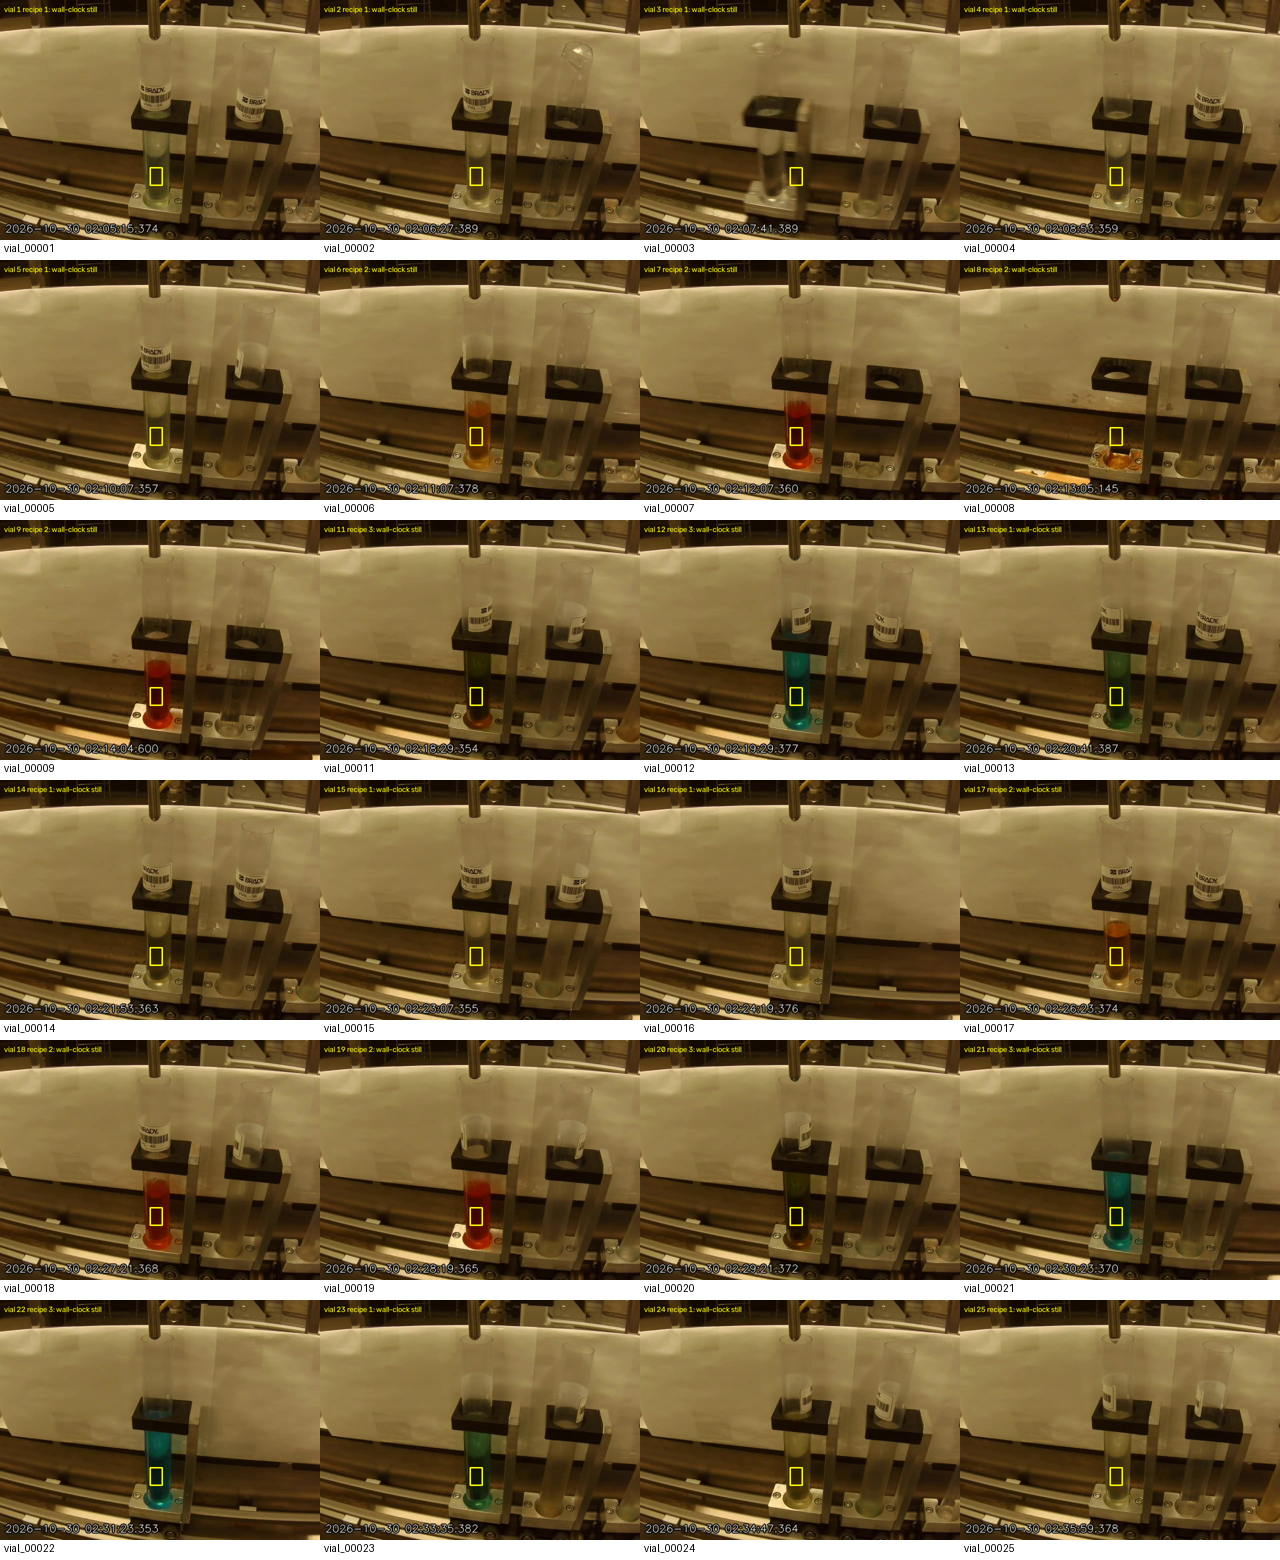

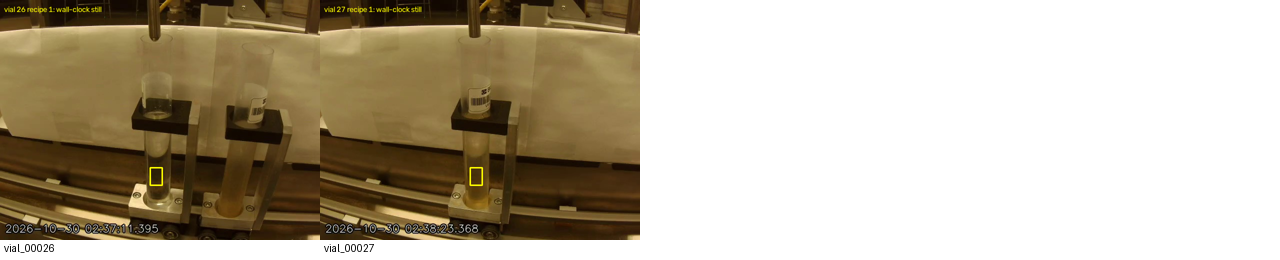

In [ ]:
if measurements.empty:
    print('No full-vial measurements: supply labels and the matching recording.')
else:
    columns = [c for c in ['session_id', 'vial', 'recipe_id', 'start_s', 'end_s',
                           'sample_times_s', 'actual_source_times_s', 'source_clock',
                           'source_clock_verified', 'source_timestamp_age_s', 'r', 'g', 'b',
                           'L', 'a', 'lab_b', 'usable', 'quality_flags', 'volume_source'] if c in measurements]
    display(measurements[columns])
for contact in sorted(OUTPUT.glob('alignment_roi_*.png'))[:4]:
    display(Image(filename=str(contact), width=1100))

## 3. Camera accuracy and stable-vial repeatability

A linear-RGB matrix needs held-out chart validation. At least five unchanged
physical controls need five independent captures each in two sessions.
Worst within-control variation and chart p95 error must both be below 2.2/3.
Alignment must be reviewed, with locked settings or a per-frame reference.

An identity transform, automatic white balance, and many adjacent production
frames cannot establish this proof. Uncertainty and production decisions remain
pending until the evidence passes for this exact calibration fingerprint.

In [ ]:
display(pd.Series({
    'camera_id': result['calibration'].camera_id,
    'calibration_id': result['calibration'].calibration_id,
    'chart_validation_delta_e': result['calibration'].validation_delta_e,
    'repeatability_proven': result['repeatability']['proven'],
    'blocking_reasons': result['repeatability']['reasons'],
}))
display(pd.DataFrame(result['repeatability']['controls']))

camera_id                                                           vial_fill
calibration_id                                           4b36c670a1f71a29f9f8
chart_validation_delta_e                                                   ()
repeatability_proven                                                    False
blocking_reasons            [Camera calibration has no saved alignment/ROI...
dtype: object

""


## 4. Clean references and observed recovery curves

Independent verified clean runs are preferred. Otherwise stable tails are marked
as **surrogates**. Vials used for a same-run tail target are withheld from that
run's evaluated curve. Surrogates never train the clean or carryover model.

Recovery needs three consecutive usable observations with ΔE00 **< 2.2**.
We record both the first vial in the streak and the later confirmation point,
in vials, mL and seconds. Insufficient follow-up or another recipe change causes
right censoring; the last observed vial is not invented as a clearance point.
Volume uses requested mL unless measured `dispensed_ml` was supplied.

,run_id,recipe_id,source,source_runs,excluded_vial_keys,rgb,lab
0,10_29_26/run2,2,missing,[],[],None,None
1,10_29_26/run3,3,other_run_tail_surrogate,[10_29_26/run6],[],"[10.0, 25.5, 15.5]","[7.38225429513346, -8.332138827010088, 4.17105..."
2,10_29_26/run4,1,other_run_tail_surrogate,[10_29_26/run1],[],"[59.5, 44.5, 14.5]","[19.29675116655401, 2.9343467101089757, 21.430..."
3,10_29_26/run5,2,missing,[],[],None,None
4,10_29_26/run6,3,same_run_tail_surrogate,[10_29_26/run6],"[10_29_26/vial21, 10_29_26/vial22]","[10.0, 25.5, 15.5]","[7.38225429513346, -8.332138827010088, 4.17105..."
5,10_29_26/run7,1,other_run_tail_surrogate,[10_29_26/run1],[],"[59.5, 44.5, 14.5]","[19.29675116655401, 2.9343467101089757, 21.430..."


,transition_id,vial_in_run,cumulative_ml,delta_e_to_clean,target_source,target_withheld,usable
0,10_29_26/run2,1,45.0,NaN,missing,False,False
1,10_29_26/run2,2,90.0,NaN,missing,False,False
2,10_29_26/run2,3,135.0,NaN,missing,False,False
3,10_29_26/run2,4,180.0,NaN,missing,False,False
4,10_29_26/run2,5,225.0,NaN,missing,False,False
5,10_29_26/run3,1,75.0,NaN,other_run_tail_surrogate,False,False
6,10_29_26/run3,2,150.0,0.899190,other_run_tail_surrogate,False,True
7,10_29_26/run4,1,75.0,14.938838,other_run_tail_surrogate,False,True
8,10_29_26/run4,2,150.0,4.273468,other_run_tail_surrogate,False,True
9,10_29_26/run4,3,225.0,3.003990,other_run_tail_surrogate,False,True


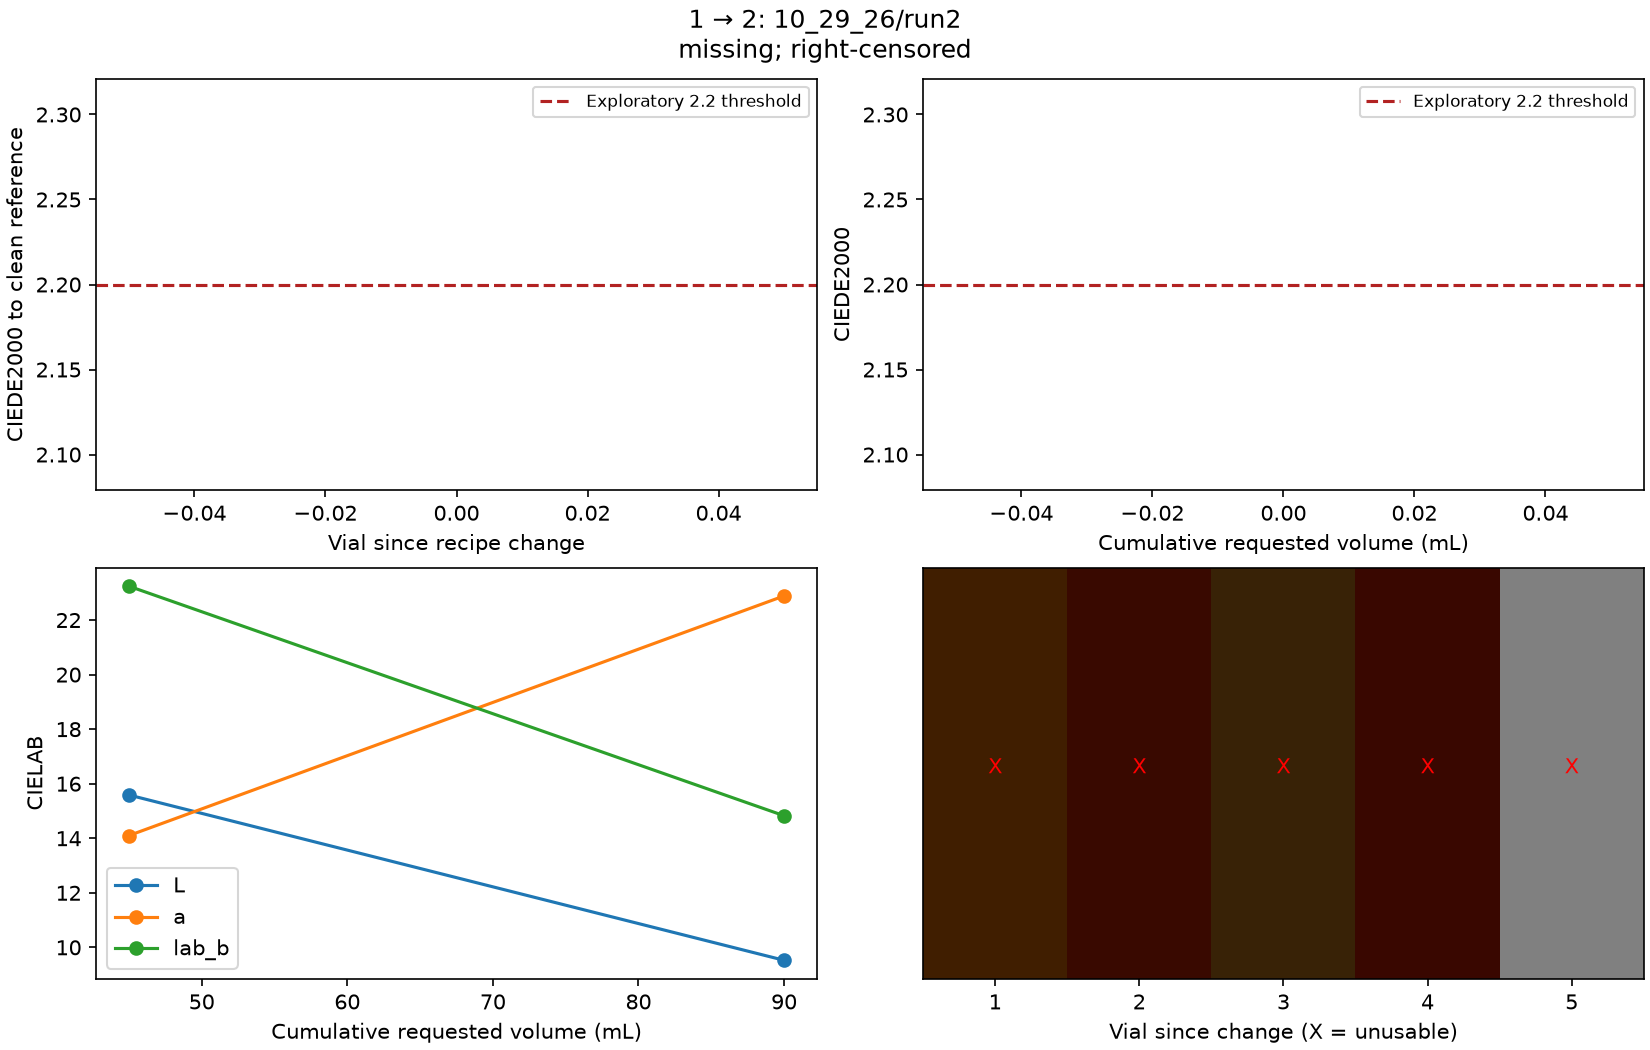

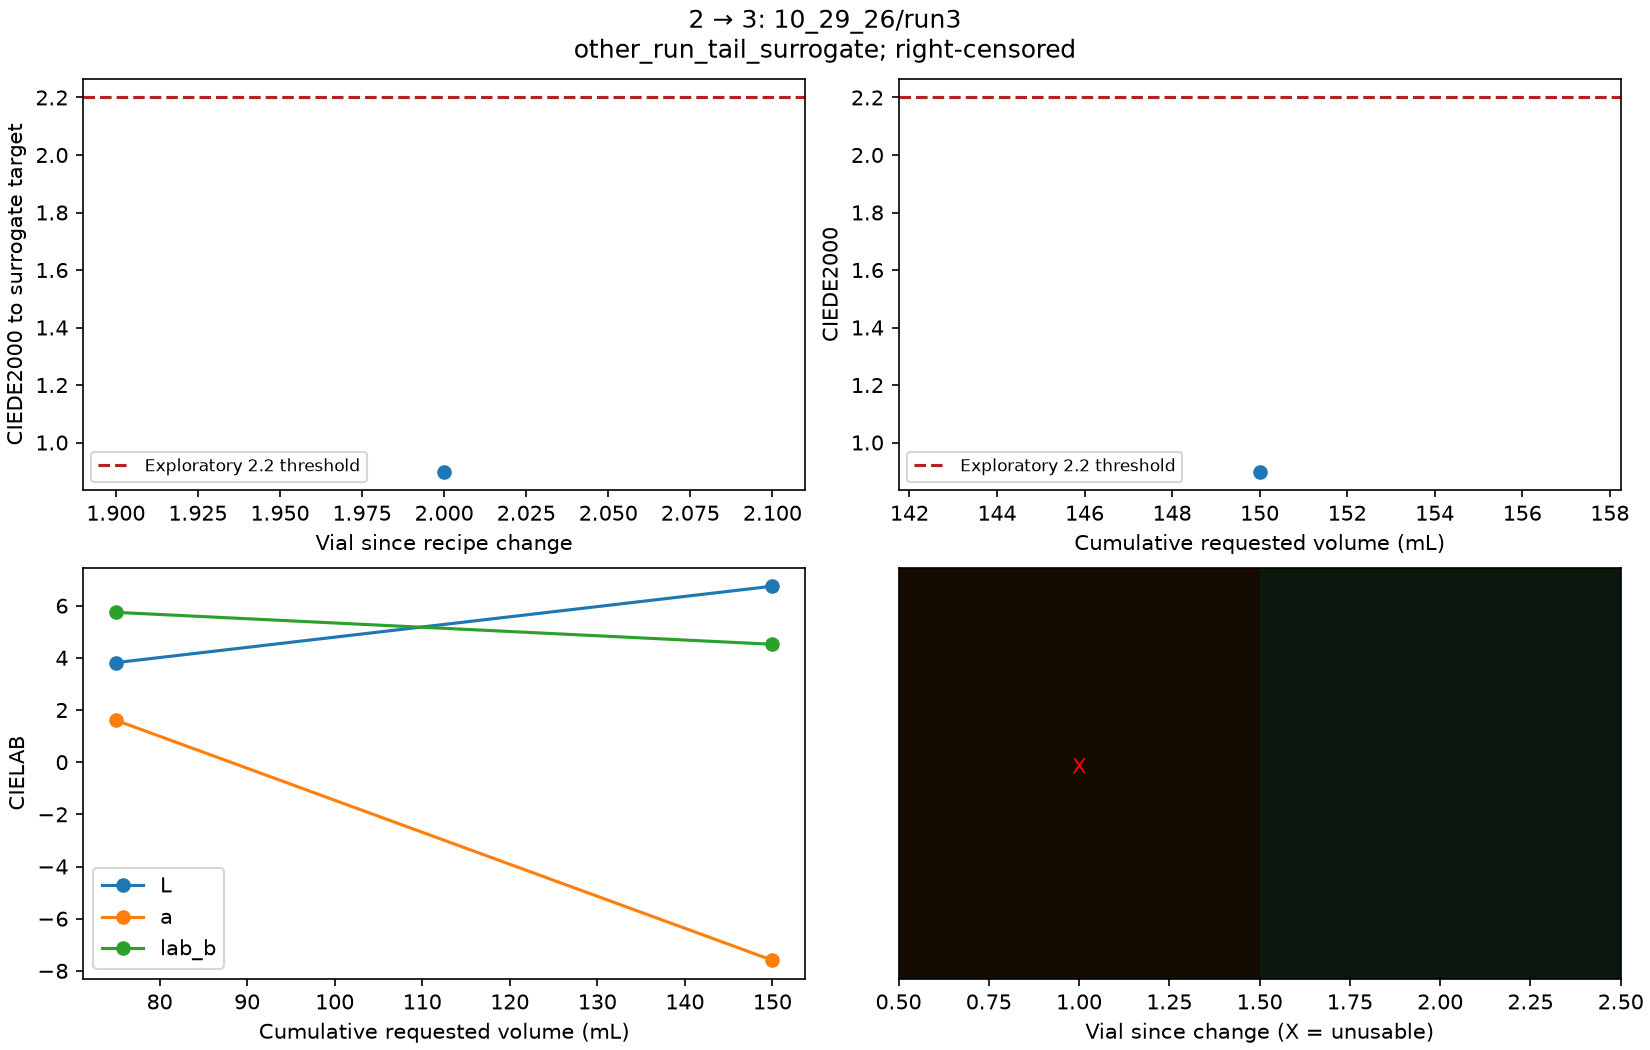

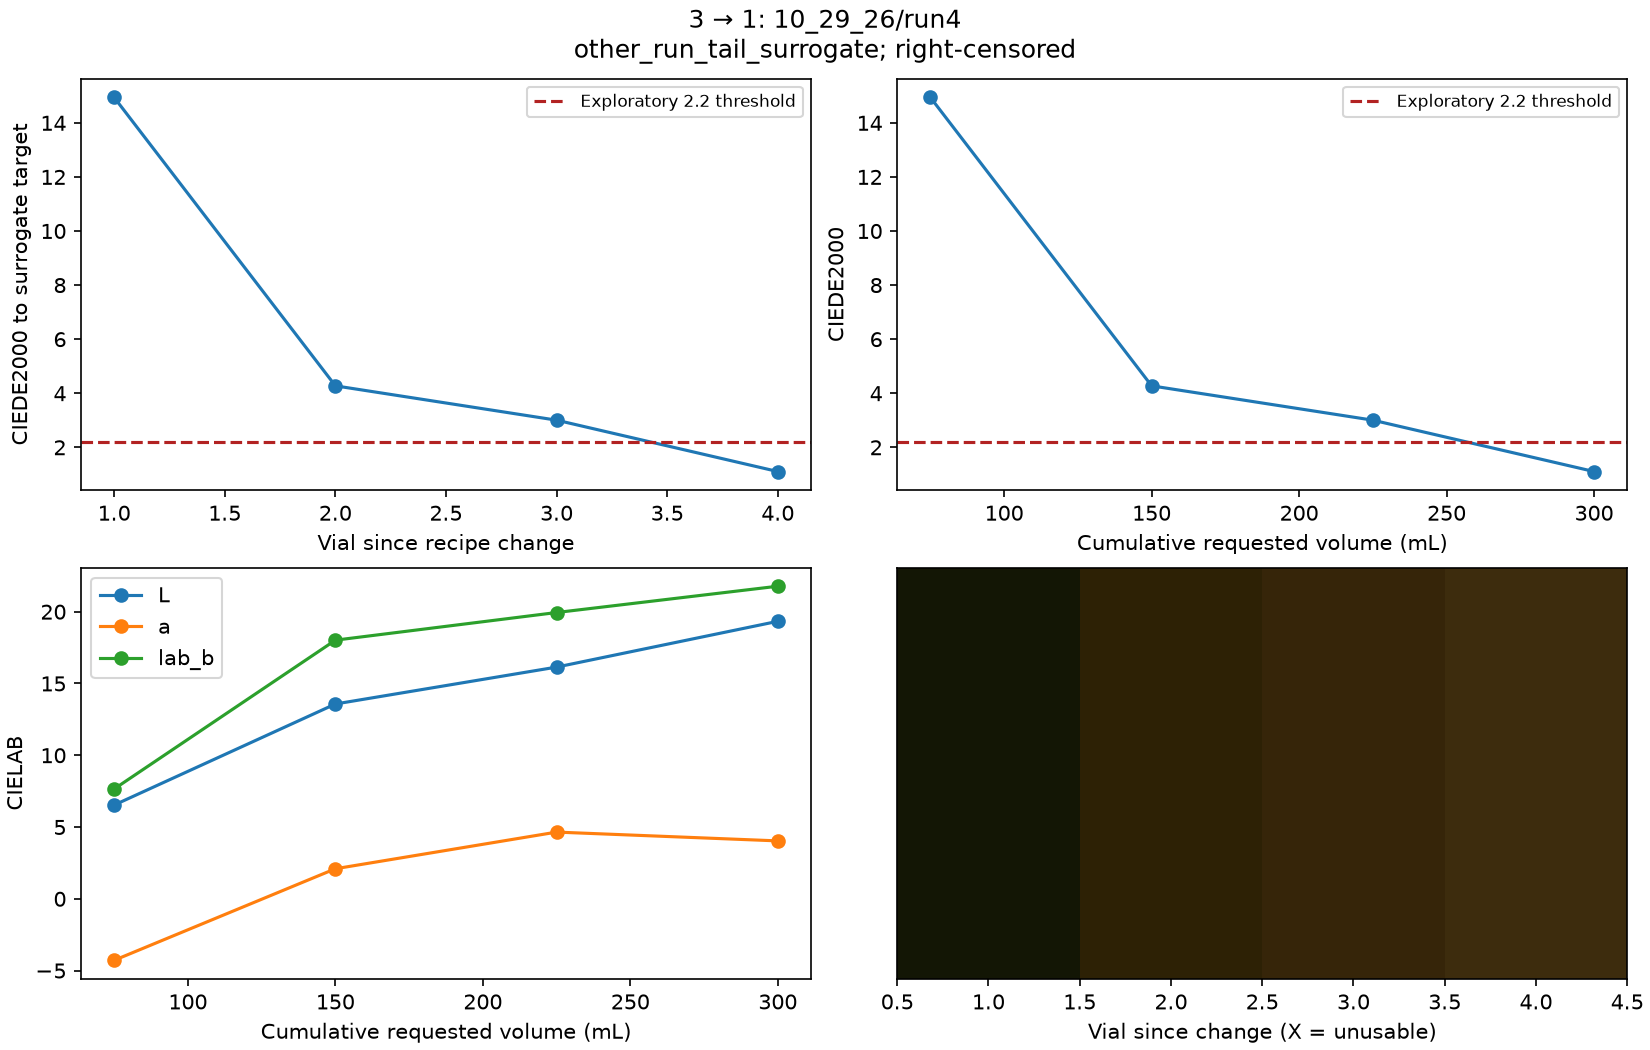

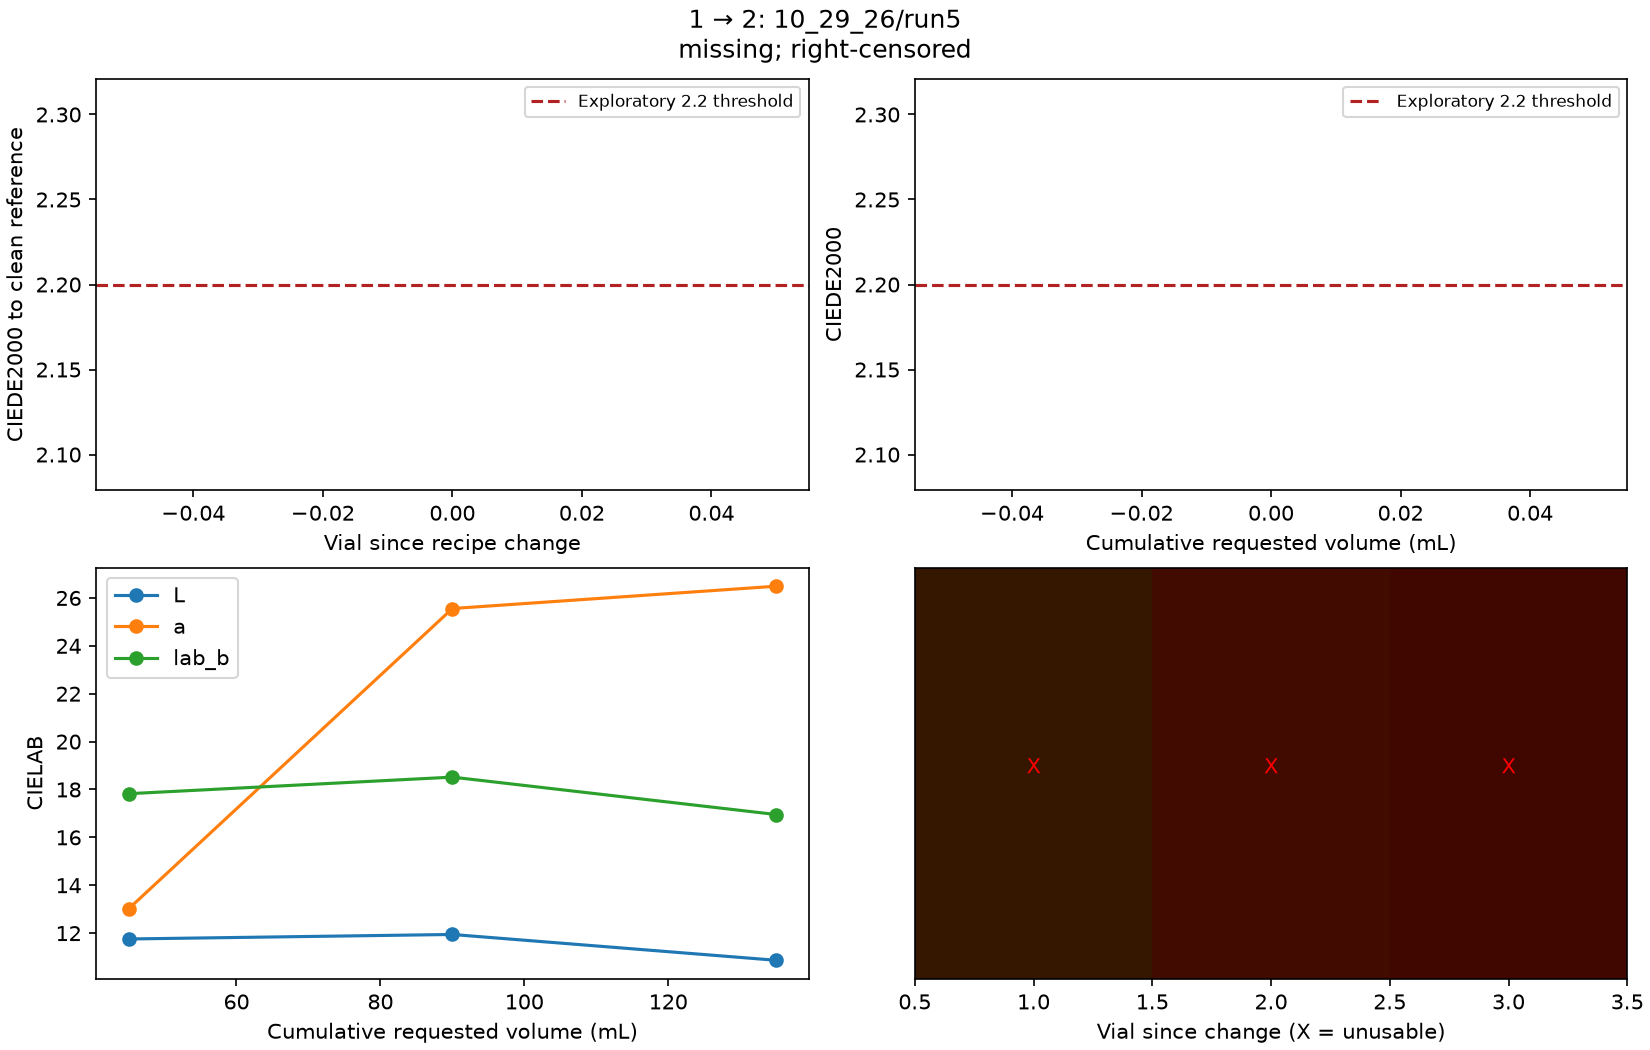

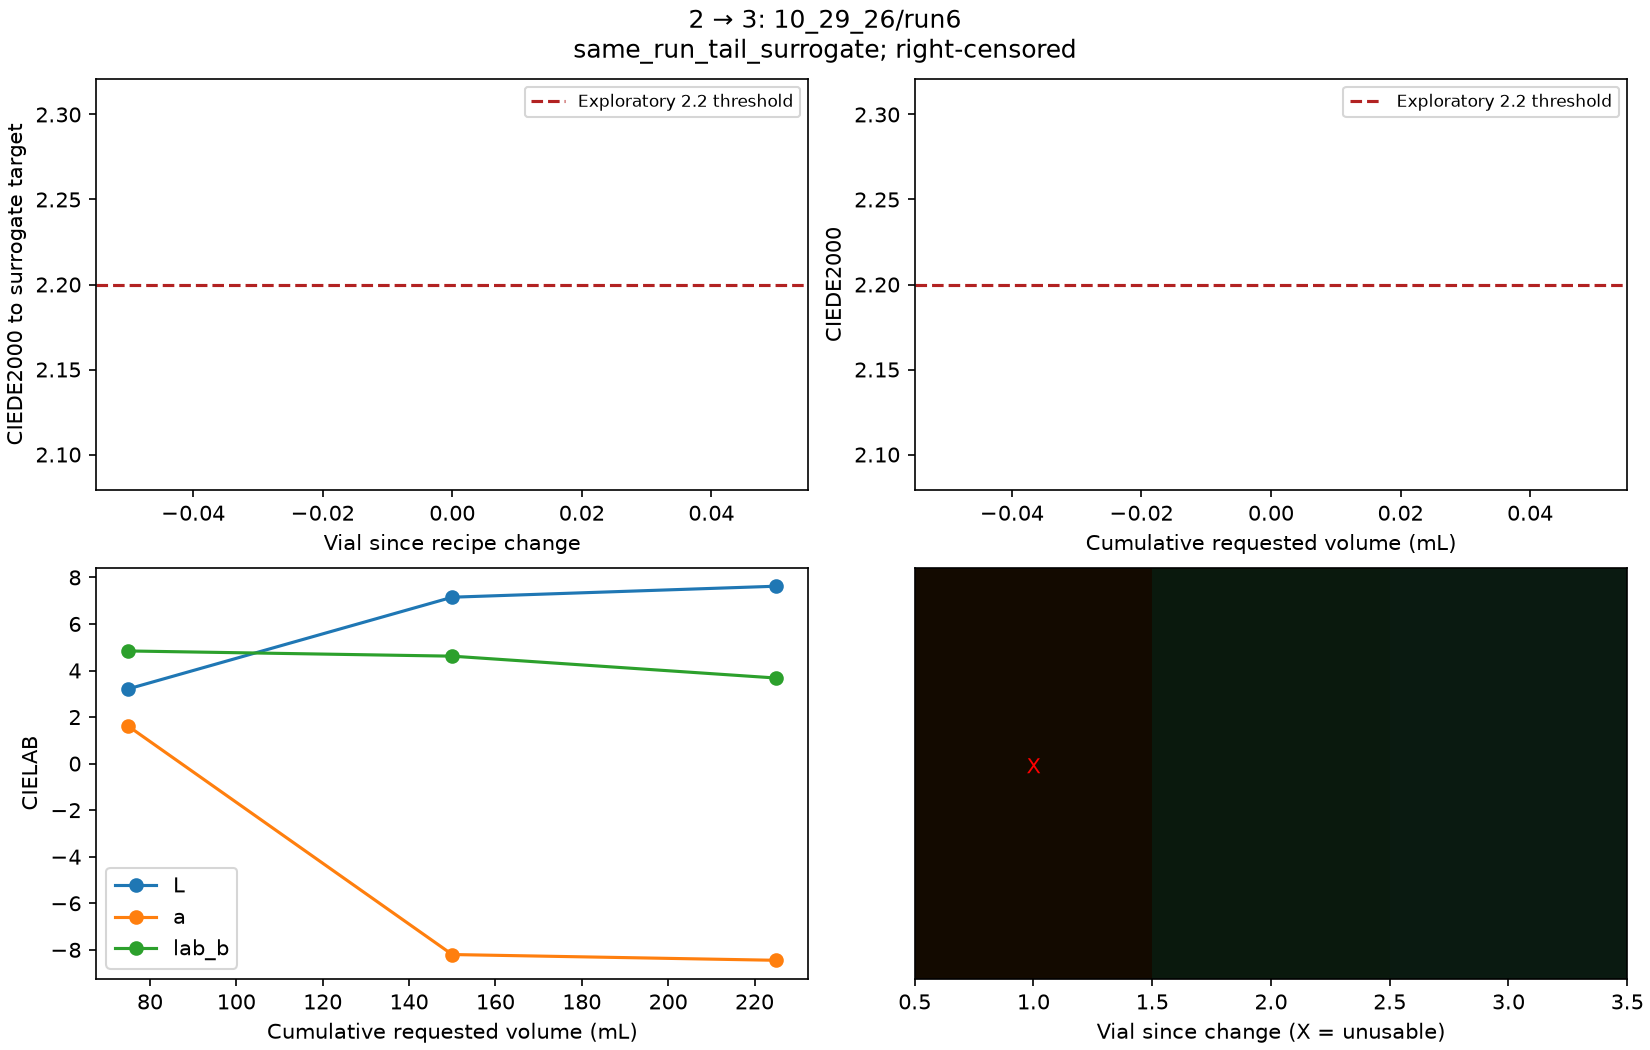

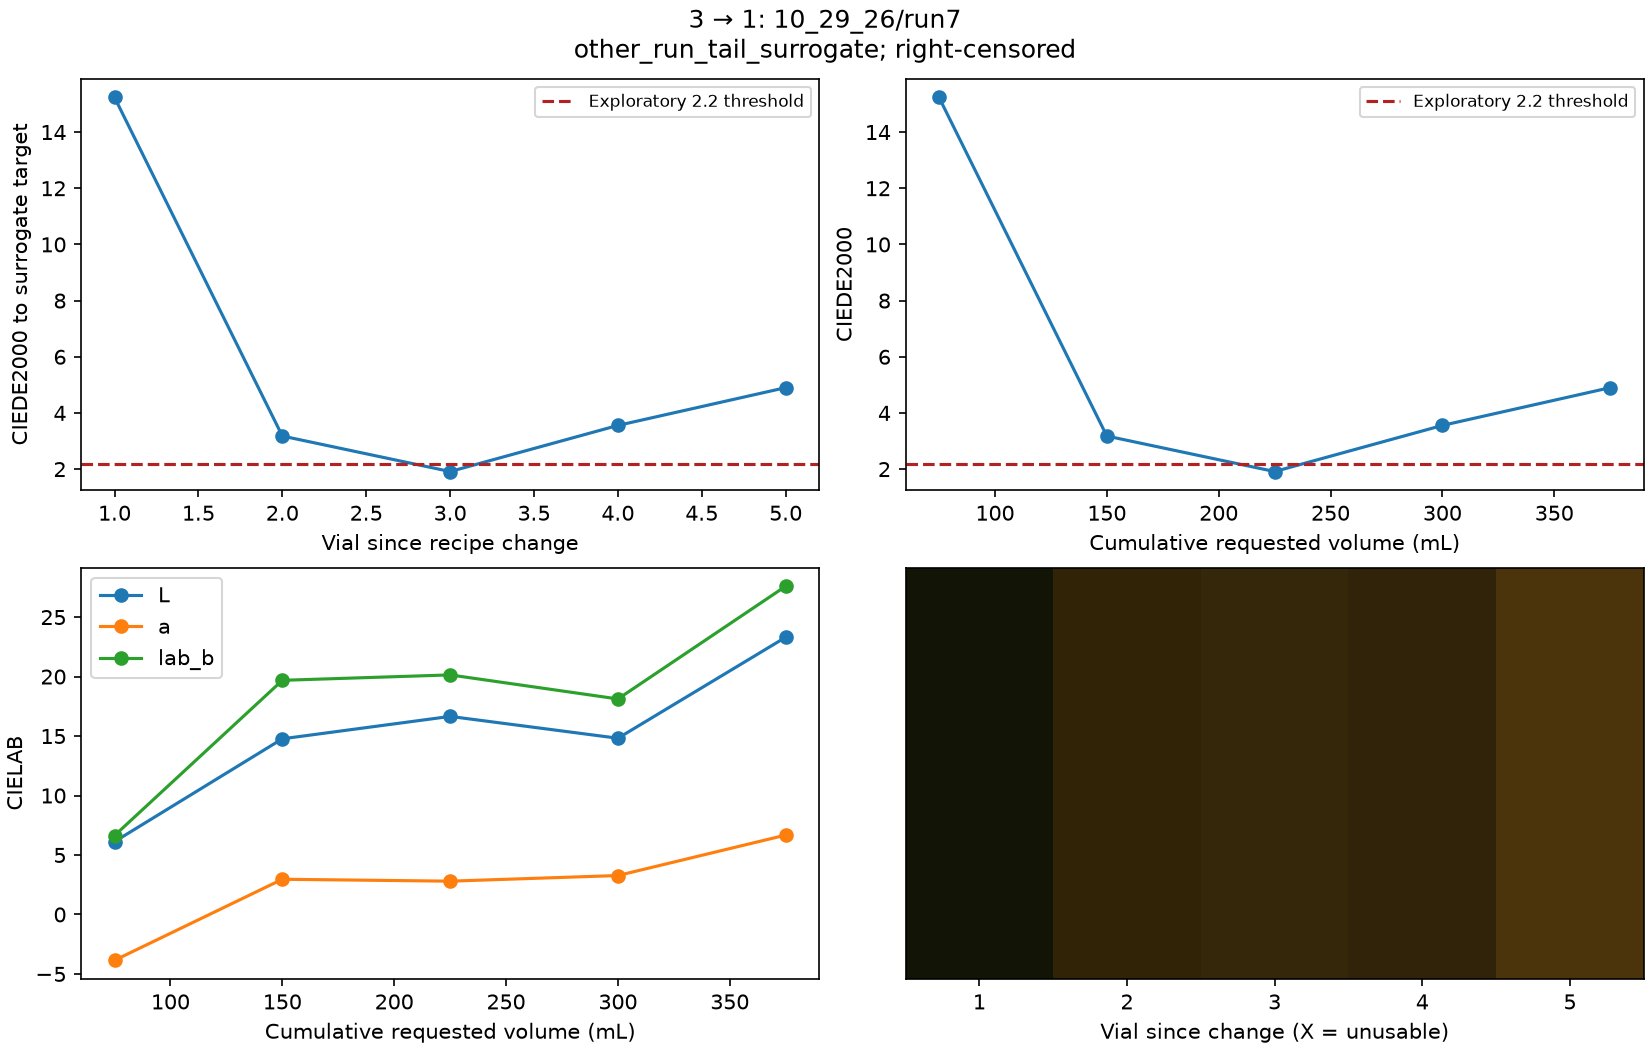

In [ ]:
display(pd.DataFrame(result['targets']))
if not curves.empty:
    display(curves[['transition_id', 'vial_in_run', 'cumulative_ml',
                    'delta_e_to_clean', 'target_source', 'target_withheld', 'usable']])
for figure in sorted((OUTPUT / 'recovery_plots').glob('*.png')):
    display(Image(filename=str(figure), width=1000))

## 5. Rank observed transitions and count independent evidence

Completed and right-censored transitions are kept separate. A censored transition
may be slow, or simply insufficiently observed. The directed heatmap retains
that distinction. Never rank a censored short recording as a fast recovery.

Minimum support for evaluating one shared decay: five transitions in three
independent sessions, each with four usable vials and an independent clean
target. Counts are identifiability checks, not a statistical power calculation.
Additional frames of one experiment do not supply independent transitions.

Completed recoveries, longest volume first:


,transition_id,session_id,previous_recipe_id,next_recipe_id,previous_total_processed_ml,flush_ml,target_source,previous_composition_ml,next_composition_ml,first_vial,last_observed_vial,observed_vials,usable_curve_vials,initial_delta_e,right_censored,censor_reason,observed_volume_ml,vials_to_clear,volume_to_clear_ml,seconds_to_clear,clearance_confirmed_at_vial,volume_to_confirm_ml,low_quality,volume_source,volume_history_usable,recovery_scope,production_status,direction


Right-censored or low-quality transitions:


,transition_id,session_id,previous_recipe_id,next_recipe_id,previous_total_processed_ml,flush_ml,target_source,previous_composition_ml,next_composition_ml,first_vial,last_observed_vial,observed_vials,usable_curve_vials,initial_delta_e,right_censored,censor_reason,observed_volume_ml,vials_to_clear,volume_to_clear_ml,seconds_to_clear,clearance_confirmed_at_vial,volume_to_confirm_ml,low_quality,volume_source,volume_history_usable,recovery_scope,production_status,direction
0,10_29_26/run2,10_29_26,1,2,375.0,NaN,missing,"{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}",6,10,5,0,NaN,True,no_independent_target_or_stable_tail,225.0,None,None,None,None,None,True,requested_proxy,False,exploratory_surrogate,PENDING,NaN
1,10_29_26/run3,10_29_26,2,3,225.0,NaN,other_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}",11,12,2,1,NaN,True,insufficient_followup,150.0,None,None,None,None,None,True,requested_proxy,True,exploratory_surrogate,PENDING,unknown
2,10_29_26/run4,10_29_26,3,1,150.0,NaN,other_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}","{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}",13,16,4,4,14.938838,True,session_ended_or_recipe_changed_before_confirm...,300.0,None,None,None,None,None,False,requested_proxy,True,exploratory_surrogate,PENDING,dark_to_light
3,10_29_26/run5,10_29_26,1,2,300.0,NaN,missing,"{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}",17,19,3,0,NaN,True,no_independent_target_or_stable_tail,135.0,None,None,None,None,None,True,requested_proxy,True,exploratory_surrogate,PENDING,NaN
4,10_29_26/run6,10_29_26,2,3,135.0,NaN,same_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}",20,22,3,0,NaN,True,session_ended_or_recipe_changed_before_confirm...,225.0,None,None,None,None,None,True,requested_proxy,True,exploratory_surrogate,PENDING,unknown
5,10_29_26/run7,10_29_26,3,1,225.0,NaN,other_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}","{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}",23,27,5,5,15.231748,True,session_ended_or_recipe_changed_before_confirm...,375.0,None,None,None,None,None,False,requested_proxy,True,exploratory_surrogate,PENDING,dark_to_light


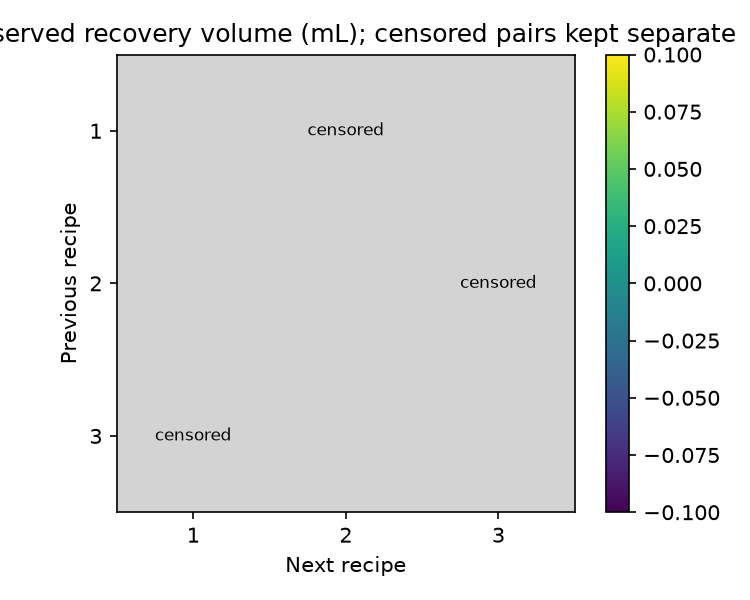

transitions                                                                      6
sessions                                                                         1
qualified_transitions                                                           []
qualified_sessions                                                               0
shared_decay_supported                                                       False
transition_specific_supported                                                False
repeated_supported_pairs                                                        []
reason                           Need at least five transitions in three sessio...
limitation                       Counts are minimum identifiability checks, not...
dtype: object

,previous_recipe_id,next_recipe_id,occurrences,independent_sessions
0,1,2,2,1
1,2,3,2,1
2,3,1,2,1


In [ ]:
if not summary.empty:
    completed = summary[~summary.right_censored].sort_values('volume_to_clear_ml', ascending=False)
    censored = summary[summary.right_censored]
    print('Completed recoveries, longest volume first:')
    display(completed)
    print('Right-censored or low-quality transitions:')
    display(censored)
heatmap = OUTPUT / 'transition_ranking_heatmap.png'
if heatmap.exists():
    display(Image(filename=str(heatmap), width=900))
display(pd.Series({k: v for k, v in result['support'].items() if k != 'directed_pairs'}))
display(pd.DataFrame(result['support'].get('directed_pairs', [])))

## 6. Fit the clean optical-density model

Effective nonnegative T200/T400 absorption is fitted in **linear RGB relative to
independent measured T100 blanks**. Clean controls are aggregated by run and
whole recipes are held out. Tank-top Lab is provenance, not an assumed vial
absorption coefficient. Recipes outside the measured simplex are unsupported.
When controls are missing or rank deficient, the artifact contains a clear
reason and no invented coefficients.

In [ ]:
model = result['clean_model']
if model is None:
    print('Clean model:', report['clean_model_status'], report['clean_model_reason'])
else:
    display(pd.DataFrame(model.absorbance, index=['T100 blank', 'T200', 'T400'], columns=['R', 'G', 'B']))
    display(pd.Series({k: v for k, v in model.validation.items() if k != 'folds'}))
    display(pd.DataFrame(model.validation['folds']))
    # Reloadable artifact: CleanOpticalModel.from_dict(model.to_dict()).predict(recipe)

Clean model: insufficient_data Independent clean-vial controls are missing.


## 7. Fit the simplest supported carryover decay

The candidate is one shared exponential tau with a signed OD residual vector per
observed transition. It integrates the state over each vial's collection volume.
Whole collection sessions are held out. Their first vial initializes the
residual, and only later vials are scored against zero-carryover and constant
baselines. The candidate must improve both by 10% and have an identifiable tau.

This is a **conditional recovery forecast after the first observed vial**. It
does not claim to predict arbitrary first-vial contamination, flush/loading
effects or chemical purity. Unsupported data leaves tau null. A bootstrap tau
interval requires proven camera repeatability and at least five sessions.

In [ ]:
display(pd.Series({k: v for k, v in result['carryover'].items()
                   if k not in ['validation', 'transition_amplitudes_od']}))
display(pd.DataFrame(result['carryover']['validation']))

kind                                    shared_single_exponential_od
status                                             insufficient_data
tau_ml                                                           NaN
tau_interval_ml                                                  NaN
scope                 conditional_recovery_after_first_observed_vial
reason             Need at least five transitions in three sessio...
limitation         No transition-specific, adsorption or multi-ex...
calibration_id                                  4b36c670a1f71a29f9f8
blank_source                                 ratio_cancels_reference
dtype: str

""


## 8. Production gate and exported artifacts

Decisions compare observed color to the **clean optical prediction**, never the
predicted contaminated color. Camera proof, independent clean-model validation
and interpolation support are mandatory. Only then is ΔE00 < 2.2 a pass and
ΔE00 ≥ 2.2 a fail. Until then the status is `PENDING` and uncertainty is null.

Every invocation gets its own export directory; stale successful fits cannot
appear to belong to a later incomplete run. The existing operator API is not
automatically enabled by exploratory notebook output.

In [ ]:
if not measurements.empty:
    display(measurements[['vial_key', 'recipe_id', 'production_status',
                          'production_delta_e_to_clean', 'prediction_error_p95_delta_e']])
print('Production decisions enabled:', report['production_decisions_enabled'])
print('Exports:', OUTPUT)
display(pd.DataFrame({'file': sorted(str(p.relative_to(OUTPUT)) for p in OUTPUT.iterdir() if p.is_file())}))
print('Remaining limitations:', *report['limitations'], sep='\n  ')

,vial_key,recipe_id,production_status,production_delta_e_to_clean,prediction_error_p95_delta_e
0,10_29_26/vial1,1,PENDING,NaN,NaN
1,10_29_26/vial2,1,PENDING,NaN,NaN
2,10_29_26/vial3,1,PENDING,NaN,NaN
3,10_29_26/vial4,1,PENDING,NaN,NaN
4,10_29_26/vial5,1,PENDING,NaN,NaN
5,10_29_26/vial6,2,PENDING,NaN,NaN
6,10_29_26/vial7,2,PENDING,NaN,NaN
7,10_29_26/vial8,2,PENDING,NaN,NaN
8,10_29_26/vial9,2,PENDING,NaN,NaN
9,10_29_26/vial10,2,PENDING,NaN,NaN


Production decisions enabled: False
Exports: outputs/transition_analysis/20261030T233959Z_364c56d5


,file
0,alignment_roi_session_1_1.png
1,alignment_roi_session_1_2.png
2,analysis_report.json
3,camera_repeatability.json
4,carryover_model_parameters.json
5,clean_optical_model.json
6,label_transition_inventory.csv
7,normalized_vial_labels.csv
8,recipe_clean_targets.json
9,recipe_run_inventory.csv


Remaining limitations:
  Observed curve thresholds are exploratory until camera and clean-model validation pass.
  Stable run tails are surrogate targets, never certified clean controls.
  Censored transitions are reported separately from completed recoveries.
  Requested mL are throughput proxies unless measured dispensed_ml is supplied.
  Tank baseline colors are not assumed equal to vial-camera colors.
  A single session cannot establish general carryover behavior.
